<a href="https://colab.research.google.com/github/WenqiaoDuan/Problem-Set-3-Econ_5200_PS3.ipynb/blob/main/%E2%80%9Cps3_starter_ipynb%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [44]:
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

# The two-by-two, by hand: mean employment by state, before and after
means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")

410 restaurants: 331 NJ, 79 PA
               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [45]:
import statsmodels.formula.api as smf

# Convert wide data to long format
ck_long = ck.reset_index().melt(
    id_vars=["index", "STATE"],
    value_vars=["fte_before", "fte_after"],
    var_name="period",
    value_name="fte"
)

ck_long["post"] = (ck_long["period"] == "fte_after").astype(int)
ck_long = ck_long.dropna(subset=["fte"])

# DiD regression
fit_ck = smf.ols("fte ~ STATE * post", data=ck_long).fit()

print(fit_ck.params.round(3))
print(f"2x2 by hand: {did:.3f}")
print(f"Regression interaction: {fit_ck.params['STATE:post']:.3f}")

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64
2x2 by hand: 2.754
Regression interaction: 2.754


*Your answer here.*

I converted the data from wide format to long format and ran a DiD regression. The interaction coefficient is 2.754, which matches the 2*2 DiD result.

The STATE coefficient (-2.892) shows that NJ had lower employment than PA before the minimum wage increase. It is not causal because the two states may have different characteristics.

The post coefficient (-2.166) shows that employment in PA decreased over time. It is not causal because other factors may have affected employment during this period.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [46]:
rng = np.random.default_rng(21)

NEVER = 10**9

# Adoption over a four-year window
board_start = {
    0: 3, 1: 3,
    2: 4, 3: 4,
    4: 5, 5: 5,
    6: 6, 7: NEVER
}

COUNTIES_PER_BOARD = 5
PERIODS = 12
GROWTH = 1.0

rows = []

for board, g in board_start.items():

    # Shared shock for all counties in the same board and year
    shock = rng.normal(0, 0.3, PERIODS)

    for k in range(COUNTIES_PER_BOARD):
        county = f"b{board}c{k}"
        fe = rng.normal(0, 1)

        for t in range(PERIODS):
            eff = GROWTH * (t - g + 1) if t >= g else 0.0

            y = (
                fe
                + 0.1 * t
                + shock[t]
                + eff
                + rng.normal(0, 0.5)
            )

            rows.append((
                county, board, g, t,
                int(t >= g), shock[t], eff, y
            ))

counties = pd.DataFrame(
    rows,
    columns=[
        "county", "board", "g", "t",
        "D", "board_shock", "true_eff", "y"
    ]
)

# True average treatment effect on treated county-years
true_att = counties.loc[
    counties["D"] == 1, "true_eff"
].mean()

print("Counties:", counties["county"].nunique())
print("Boards:", counties["board"].nunique())
print("Periods:", counties["t"].nunique())
print("Observations:", len(counties))
print(f"True ATT: {true_att:.3f}")

Counties: 40
Boards: 8
Periods: 12
Observations: 480
True ATT: 4.426


In [47]:
twfe_counties = smf.ols(
    "y ~ D + C(county) + C(t)",
    data=counties
).fit()

twfe_est = twfe_counties.params["D"]

print(f"TWFE estimate: {twfe_est:.3f}")
print(f"True ATT: {true_att:.3f}")
print(f"Difference: {twfe_est - true_att:.3f}")

TWFE estimate: 2.084
True ATT: 4.426
Difference: -2.342


*Your answer here.*

I simulated 40 counties across 8 regional workforce boards over 12 years. Each board adopted the program at the same time, with adoption occurring in different years. One board never adopted the program. I included a treatment effect that grows with exposure and a board-level shock shared by counties in the same board and year.

The true ATT is 4.426, while the TWFE estimate is 2.084. The TWFE estimate is 2.342 lower than the true ATT, which is about 52.9% lower.
This shows that TWFE underestimates the true treatment effect in this simulation.

### Step 2.2: Decompose it (15 pts)

In [48]:
# Step 2.2: Goodman-Bacon decomposition

cohort_means = counties.groupby(["g", "t"])["y"].mean().unstack()
cohort_sizes = counties.groupby("g")["county"].nunique()

T = counties["t"].nunique()
N = counties["county"].nunique()

# Residualized treatment indicator for TWFE
D_wide = counties.pivot(index="county", columns="t", values="D")

D_resid = (
    D_wide
    - D_wide.mean(axis=1).values[:, None]
    - D_wide.mean(axis=0)
    + D_wide.values.mean()
)

var_D = (D_resid.values ** 2).mean()

def change(means, before, after):
    return means[list(after)].mean() - means[list(before)].mean()

results = []
cohorts = sorted(cohort_sizes.index)

for i, g in enumerate(cohorts):
    for h in cohorts[i + 1:]:
        share = cohort_sizes[g] * cohort_sizes[h] / N**2

        if h == NEVER:
            # Treated versus never-treated
            estimate = (
                change(cohort_means.loc[g], range(g), range(g, T))
                - change(cohort_means.loc[h], range(g), range(g, T))
            )
            weight = share * (g / T) * (1 - g / T) / var_D
            results.append((g, h, "never-treated", estimate, weight))

        else:
            # Clean: early treated, late not yet treated
            clean = (
                change(cohort_means.loc[g], range(g), range(g, h))
                - change(cohort_means.loc[h], range(g), range(g, h))
            )
            w_clean = share * (g / T) * ((h - g) / T) / var_D
            results.append((g, h, "clean", clean, w_clean))

            # Forbidden: late treated, early already treated
            forbidden = (
                change(cohort_means.loc[h], range(g, h), range(h, T))
                - change(cohort_means.loc[g], range(g, h), range(h, T))
            )
            w_forbidden = (
                share * ((h - g) / T) * ((T - h) / T) / var_D
            )
            results.append((g, h, "forbidden", forbidden, w_forbidden))

decomp = pd.DataFrame(
    results, columns=["early", "late", "type", "estimate", "weight"]
)

decomp["contribution"] = decomp["estimate"] * decomp["weight"]

print(decomp.round(3).to_string(index=False))

print("\nTotal weight:", round(decomp["weight"].sum(), 3))
print("Weighted sum:", round(decomp["contribution"].sum(), 3))
print("TWFE:", round(twfe_counties.params["D"], 3))

forbidden_weight = decomp.loc[
    decomp["type"] == "forbidden", "weight"
].sum()

print(f"Forbidden comparison weight: {forbidden_weight:.1%}")

assert np.isclose(decomp["weight"].sum(), 1.0)
assert np.isclose(
    decomp["contribution"].sum(),
    twfe_counties.params["D"]
)
print("PASS: Decomposition matches TWFE")

 early       late          type  estimate  weight  contribution
     3          4         clean     1.652   0.024         0.039
     3          4     forbidden     0.357   0.063         0.023
     3          5         clean     1.348   0.047         0.064
     3          5     forbidden    -0.405   0.110        -0.045
     3          6         clean     1.895   0.035         0.067
     3          6     forbidden    -1.116   0.071        -0.079
     3 1000000000 never-treated     5.028   0.106         0.535
     4          5         clean     0.725   0.031         0.023
     4          5     forbidden     0.119   0.055         0.007
     4          6         clean     1.602   0.031         0.050
     4          6     forbidden    -0.149   0.047        -0.007
     4 1000000000 never-treated     4.158   0.126         0.524
     5          6         clean     1.896   0.020         0.037
     5          6     forbidden     0.648   0.024         0.015
     5 1000000000 never-treated     4.17

In [49]:
treated = counties.loc[counties["D"] == 1, "true_eff"]

min_effect = treated.min()
max_effect = treated.max()
twfe_value = twfe_counties.params["D"]

print(f"Minimum true effect: {min_effect:.3f}")
print(f"Maximum true effect: {max_effect:.3f}")
print(f"TWFE estimate: {twfe_value:.3f}")

print("Outside true-effect range:",
      not (min_effect <= twfe_value <= max_effect))

Minimum true effect: 1.000
Maximum true effect: 9.000
TWFE estimate: 2.084
Outside true-effect range: False


In [50]:
# Step 2.2 — Outside-Range TWFE Demonstration
# Based on the original Step 2.1 panel

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Keep the original panel unchanged
counties_demo = counties.copy()

# Introduce heterogeneous treatment-effect growth
COHORT_GROWTH = {
    3: 20.0,
    4: 1.0,
    5: 1.0,
    6: 1.0
}

# New true treatment effects
counties_demo["new_true_eff"] = counties_demo.apply(
    lambda row: (
        COHORT_GROWTH[row["g"]] * (row["t"] - row["g"] + 1)
        if row["D"] == 1 else 0.0
    ),
    axis=1
)

# Replace only the treatment-effect component of the outcome
# Preserve fixed effects, time trends, and original random shocks
counties_demo["y"] = (
    counties_demo["y"]
    - counties_demo["true_eff"]
    + counties_demo["new_true_eff"]
)

counties_demo["true_eff"] = counties_demo["new_true_eff"]
counties_demo.drop(columns=["new_true_eff"], inplace=True)

# Re-estimate TWFE
twfe_demo = smf.ols(
    "y ~ D + C(county) + C(t)",
    data=counties_demo
).fit()

twfe_value = twfe_demo.params["D"]

# Calculate true treatment effects
treated_effects = counties_demo.loc[
    counties_demo["D"] == 1, "true_eff"
]

min_effect = treated_effects.min()
max_effect = treated_effects.max()
true_att_demo = treated_effects.mean()

# Check whether TWFE falls outside the true-effect range
outside_range = (
    twfe_value < min_effect
    or twfe_value > max_effect
)

print("=== Step 2.2: Outside-Range Demonstration ===")
print(f"Minimum true effect: {min_effect:.3f}")
print(f"Maximum true effect: {max_effect:.3f}")
print(f"True ATT: {true_att_demo:.3f}")
print(f"TWFE estimate: {twfe_value:.3f}")
print(f"Outside true-effect range: {outside_range}")

assert outside_range, "TWFE is still inside the true-effect range."

print("\nPASS: TWFE falls outside the range of true effects.")

print("\n=== Interpretation ===")
print(
    "All true treatment effects are positive, but TWFE is negative. "
    "This demonstrates that TWFE need not lie between the minimum "
    "and maximum true treatment effects when treatment effects "
    "are heterogeneous across cohorts and exposure periods."
)

=== Step 2.2: Outside-Range Demonstration ===
Minimum true effect: 1.000
Maximum true effect: 180.000
True ATT: 36.093
TWFE estimate: -5.546
Outside true-effect range: True

PASS: TWFE falls outside the range of true effects.

=== Interpretation ===
All true treatment effects are positive, but TWFE is negative. This demonstrates that TWFE need not lie between the minimum and maximum true treatment effects when treatment effects are heterogeneous across cohorts and exposure periods.


*Your answer here.*

I divided the TWFE estimate into different 2*2 DiD comparisons. In my original simulation, the weighted sum was 2.084, which matched the TWFE estimate. The forbidden comparisons used already-treated counties as controls and accounted for 37.0% of the total weight.

I then ran an additional simulation where treatment effects were different across groups and increased over time. The true treatment effects ranged from 1.000 to 180.000, and the true ATT was 36.093. However, the TWFE estimate was -5.546, which was outside this range.

This happened because TWFE used some already-treated counties as controls. When treatment effects change over time, these comparisons can give misleading results.

This example shows that TWFE can give a negative estimate even when all true treatment effects are positive. Therefore, TWFE does not always fall within the range of true treatment effects.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [51]:
# Step 3.1: Clean ATT using not-yet-treated controls
# Based on Lab 11 clean_att()

NEVER = 10**9

def clean_att(df):
    """Estimate ATT(g,t) using only not-yet-treated controls."""
    out = []

    for g in sorted(df.loc[df["g"] < NEVER, "g"].unique()):
        treated = df[df["g"] == g]

        for t in range(g, df["t"].max() + 1):
            controls = df[df["g"] > t]

            if controls.empty:
                continue

            d_tr = (
                treated.loc[treated["t"] == t, "y"].mean()
                - treated.loc[treated["t"] == g - 1, "y"].mean()
            )

            d_co = (
                controls.loc[controls["t"] == t, "y"].mean()
                - controls.loc[controls["t"] == g - 1, "y"].mean()
            )

            n = (treated["t"] == t).sum()

            out.append({
                "g": g,
                "t": t,
                "att": d_tr - d_co,
                "n": n
            })

    cells = pd.DataFrame(out)
    return cells, np.average(cells["att"], weights=cells["n"])


# Apply to the existing panel
per_cell, att_hat = clean_att(counties)

# Compare with true ATT and TWFE
truth = counties.loc[counties["D"] == 1, "true_eff"].mean()
twfe_value = twfe_counties.params["D"]

print(f"{'Estimator':<35}{'Estimate':>12}{'Truth':>12}")
print("-" * 59)

print(f"{'TWFE (all comparisons)':<35}"
      f"{twfe_value:>12.3f}{truth:>12.3f}")

print(f"{'Not-yet-treated controls only':<35}"
      f"{att_hat:>12.3f}{truth:>12.3f}")

print("\nNumber of clean ATT cells:", len(per_cell))
print("\nFirst five cells:")
print(per_cell.head())

print("\nAbsolute error:")
print(f"TWFE: {abs(twfe_value - truth):.3f}")
print(f"Clean ATT: {abs(att_hat - truth):.3f}")

Estimator                              Estimate       Truth
-----------------------------------------------------------
TWFE (all comparisons)                    2.084       4.426
Not-yet-treated controls only             4.774       4.426

Number of clean ATT cells: 30

First five cells:
   g  t    att   n
0  3  3  1.970  10
1  3  4  2.225  10
2  3  5  3.486  10
3  3  6  4.267  10
4  3  7  5.330  10

Absolute error:
TWFE: 2.342
Clean ATT: 0.348


*Your answer here.*

I used the clean_att() function from Lab 11 to estimate the treatment effect for each cohort and period. I only used never-treated or not-yet-treated counties as controls.

I calculated 30 clean ATT cells and averaged them based on the number of treated counties in each cell.

The true ATT is 4.426. The TWFE estimate is 2.084, while the clean ATT estimate is 4.774. The absolute error decreases from 2.342 for TWFE to 0.348 for clean ATT.

This shows that the clean ATT method gives a more accurate estimate in my simulation because it avoids using already-treated counties as controls.

### Step 3.2: The assumption you cannot test (12 pts)

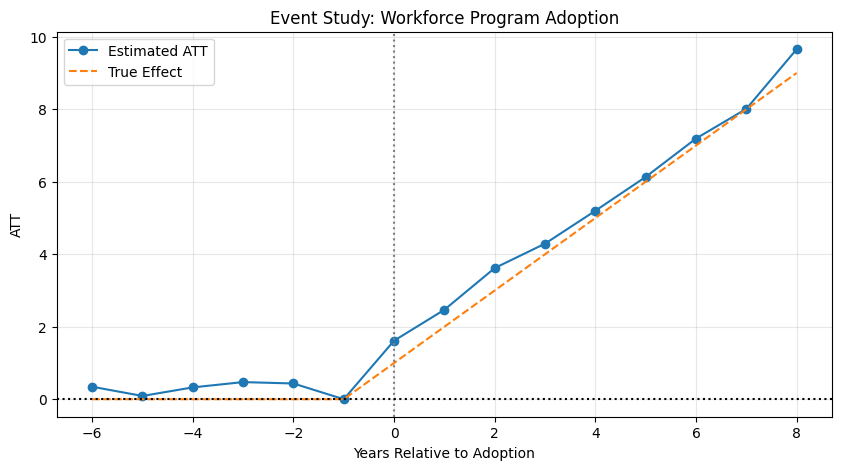

 e   att  truth
-6 0.345    0.0
-5 0.090    0.0
-4 0.326    0.0
-3 0.473    0.0
-2 0.434    0.0
-1 0.000    0.0
 0 1.615    1.0
 1 2.469    2.0
 2 3.619    3.0
 3 4.292    4.0
 4 5.199    5.0
 5 6.133    6.0
 6 7.192    7.0
 7 8.011    8.0
 8 9.656    9.0
Omitted reference period: e = -1


In [52]:
# Step 3.2: Event study using clean ATT cells

# Post-treatment event study
es = per_cell.copy()
es["e"] = es["t"] - es["g"]

post_es = (
    es.groupby("e")
    .apply(lambda x: np.average(x["att"], weights=x["n"]),
           include_groups=False)
    .reset_index(name="att")
)

# Pre-treatment estimates
pre_results = []

for g in sorted(counties.loc[counties["g"] < NEVER, "g"].unique()):
    treated = counties[counties["g"] == g]
    base = g - 1

    # Use never-treated or not-yet-treated controls
    for t in range(0, base):
        controls = counties[counties["g"] > base]

        d_tr = (
            treated.loc[treated["t"] == t, "y"].mean()
            - treated.loc[treated["t"] == base, "y"].mean()
        )

        d_co = (
            controls.loc[controls["t"] == t, "y"].mean()
            - controls.loc[controls["t"] == base, "y"].mean()
        )

        pre_results.append({
            "g": g,
            "e": t - g,
            "att": d_tr - d_co,
            "n": (treated["t"] == t).sum()
        })

pre_cells = pd.DataFrame(pre_results)

pre_es = (
    pre_cells.groupby("e")
    .apply(lambda x: np.average(x["att"], weights=x["n"]),
           include_groups=False)
    .reset_index(name="att")
)

# Reference period
reference = pd.DataFrame({"e": [-1], "att": [0.0]})

# Combine pre- and post-treatment estimates
event_study = pd.concat(
    [pre_es, reference, post_es],
    ignore_index=True
).sort_values("e")

# True treatment effect
event_study["truth"] = np.where(
    event_study["e"] >= 0,
    GROWTH * (event_study["e"] + 1),
    0.0
)

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    event_study["e"],
    event_study["att"],
    "o-",
    label="Estimated ATT"
)

plt.plot(
    event_study["e"],
    event_study["truth"],
    "--",
    label="True Effect"
)

plt.axvline(0, color="gray", linestyle=":")
plt.axhline(0, color="black", linestyle=":")

plt.xlabel("Years Relative to Adoption")
plt.ylabel("ATT")
plt.title("Event Study: Workforce Program Adoption")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(event_study.round(3).to_string(index=False))
print("Omitted reference period: e = -1")

*Your answer here.*

I used the clean ATT method to build an event study, using only never-treated or not-yet-treated counties as controls. I omitted event time -1, the year before treatment, as the reference period.

Before treatment, the estimates range from 0.090 to 0.473, which are close to zero. After treatment, the estimates increase from 1.615 to 9.656.

The pre-treatment results are consistent with parallel trends, but they do not prove the assumption. We cannot know whether the groups would have followed similar trends after treatment without the program. We must also assume that counties did not change their behavior before treatment because they expected the program. These assumptions cannot be fully tested with the data.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [53]:
# Step 3.3: Compare standard errors

formula = "y ~ D + C(county) + C(t)"

fits = {
    "default (iid)": smf.ols(formula, data=counties).fit(),

    "clustered by county": smf.ols(formula, data=counties).fit(
        cov_type="cluster",
        cov_kwds={"groups": counties["county"]}
    ),

    "clustered by board": smf.ols(formula, data=counties).fit(
        cov_type="cluster",
        cov_kwds={"groups": counties["board"]}
    )
}

print(f"{'Method':<24}{'Estimate':>12}{'Std Error':>12}{'Clusters':>12}")
print("-" * 60)

for label, fit in fits.items():
    if label == "default (iid)":
        n_clusters = "none"
    elif label == "clustered by county":
        n_clusters = "40"
    else:
        n_clusters = "8"

    print(
        f"{label:<24}"
        f"{fit.params['D']:>12.3f}"
        f"{fit.bse['D']:>12.3f}"
        f"{n_clusters:>12}"
    )

Method                      Estimate   Std Error    Clusters
------------------------------------------------------------
default (iid)                  2.084       0.207        none
clustered by county            2.084       0.517          40
clustered by board             2.084       1.197           8


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [54]:
import os
os.makedirs("src", exist_ok=True)

In [55]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit, extending Lab 11."""
from __future__ import annotations

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.regression.linear_model import RegressionResultsWrapper

NEVER = 10**9


# Lab 11 functions
def two_by_two(df: pd.DataFrame, outcome: str,
               treated: str, post: str) -> float:
    """Calculate the canonical 2x2 DiD estimate."""
    g = df.groupby([treated, post])[outcome].mean()
    return float((g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0]))


def att_by_cohort_period(df: pd.DataFrame, time: str,
                         outcome: str, cohort: str) -> pd.DataFrame:
    """Estimate ATT(g,t) using only not-yet-treated controls."""
    out = []
    cohorts = sorted(c for c in df[cohort].unique() if c < NEVER)

    for g in cohorts:
        tr = df[df[cohort] == g]

        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]

            if co.empty or (tr[time] == g - 1).sum() == 0:
                continue

            d_tr = (
                tr.loc[tr[time] == t, outcome].mean()
                - tr.loc[tr[time] == g - 1, outcome].mean()
            )
            d_co = (
                co.loc[co[time] == t, outcome].mean()
                - co.loc[co[time] == g - 1, outcome].mean()
            )

            out.append({
                "g": g, "t": t, "e": t - g,
                "att": d_tr - d_co,
                "n": int((tr[time] == t).sum())
            })

    return pd.DataFrame(out)


def overall_att(cells: pd.DataFrame) -> float:
    """Calculate the size-weighted average ATT."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Aggregate ATT estimates by event time."""
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({
            "e": e,
            "att": np.average(group["att"], weights=group["n"])
        })
    return pd.DataFrame(rows)


def cluster_se_ratio(fit_iid, fit_clustered, param: str) -> float:
    """Calculate the ratio of clustered to default standard errors."""
    return float(fit_clustered.bse[param] / fit_iid.bse[param])


# Notebook function
def clean_att(df: pd.DataFrame) -> tuple[pd.DataFrame, float]:
    """Estimate clean ATT using not-yet-treated controls."""
    cells = att_by_cohort_period(df, "t", "y", "g")
    return cells, overall_att(cells)


# Step 3.3
def clustered_inference(
    df: pd.DataFrame,
    formula: str,
    cluster_col: str
) -> RegressionResultsWrapper:
    """Fit OLS with cluster-robust standard errors."""
    if cluster_col not in df.columns:
        raise ValueError(f"Column {cluster_col} not found")

    return smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster_col]}
    )


if __name__ == "__main__":
    test = pd.DataFrame({
        "treated": [0, 0, 1, 1],
        "post": [0, 1, 0, 1],
        "y": [10, 12, 11, 15]
    })

    assert np.isclose(
        two_by_two(test, "y", "treated", "post"), 2.0
    )

    test_cells = pd.DataFrame({
        "e": [0, 1],
        "att": [1.0, 2.0],
        "n": [10, 10]
    })

    es = event_study(test_cells)
    assert len(es) == 2
    assert np.isclose(es["att"].mean(), 1.5)

    print("PASS: Basic toolkit assertions")

Overwriting src/did_toolkit.py


In [56]:
import os
import sys
import importlib
import numpy as np

sys.path.insert(0, os.path.abspath("."))
from src import did_toolkit as dt
dt = importlib.reload(dt)

# 1. two_by_two
subset = counties[
    counties["g"].isin([3, NEVER]) &
    counties["t"].isin([2, 3])
].copy()

subset["treated"] = (subset["g"] == 3).astype(int)
subset["post"] = (subset["t"] == 3).astype(int)

result_2x2 = dt.two_by_two(
    subset, "y", "treated", "post"
)
print(f"2x2 DiD: {result_2x2:.3f}")

# 2. clean_att
cells, clean_est = dt.clean_att(counties)
print(f"Clean ATT: {clean_est:.3f}")

# 3. event_study
es = dt.event_study(cells)
print("\nEvent study:")
print(es.head())

# 4. clustered_inference
fit = dt.clustered_inference(
    counties,
    "y ~ D + C(county) + C(t)",
    "board"
)

print(f"\nTWFE estimate: {fit.params['D']:.3f}")
print(f"Board-clustered SE: {fit.bse['D']:.3f}")

# Assertions
assert len(cells) == 30
assert np.isclose(clean_est, 4.774, atol=0.001)
assert np.isclose(fit.params["D"], 2.084, atol=0.001)
assert np.isclose(fit.bse["D"], 1.197, atol=0.001)
assert len(es) > 0

print("\nPASS: All four toolkit functions work on the panel")

2x2 DiD: 1.969
Clean ATT: 4.774

Event study:
   e    att
0  0  1.615
1  1  2.469
2  2  3.619
3  3  4.292
4  4  5.199

TWFE estimate: 2.084
Board-clustered SE: 1.197

PASS: All four toolkit functions work on the panel


*Your answer here.*

I compared three types of standard errors: default, clustered by county, and clustered by board. All three methods give the same TWFE estimate of 2.084. The standard errors are 0.207, 0.517, and 1.197.

I think clustering by board is the best choice because treatment was assigned at the board level. Counties in the same board may also be affected by the same shocks.

The default method ignores these correlations. Clustering by county considers correlations within each county, but not between counties in the same board.

However, there are only 8 boards, so we should be careful when interpreting the results.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

Version1:
[Prep] Act as an applied microeconometrician who has implemented
cluster-robust inference for panels with very few clusters.

[Request] Implement the wild cluster bootstrap exactly to the
specification below, for a county-year panel with treatment assigned
at the level of eight regional boards. Impose the null, apply
Rademacher weights at the cluster level, enumerate all 256 weight
vectors rather than resampling, and return the bootstrap p-value for
the treatment coefficient.
<paste the six numbered steps here>

[Iterate] numpy, pandas and statsmodels only. Reuse my panel's column
names. The function must accept the cluster variable as an argument.

[Mechanism Check] Explain why the weights are applied to residuals at
the CLUSTER level rather than the observation level, why imposing the
null matters, and what changes when the number of clusters drops
below roughly ten.

[Evaluate] Run it on my panel and compare the p-value against the
naive cluster-robust one. Tell me which conclusion changes.

In [57]:

import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm


def wild_cluster_bootstrap(
    panel,
    outcome,
    treatment,
    cluster,
    controls=None,
    alpha=0.05
):
    """
    Exact null-imposed wild cluster bootstrap.

    Uses:
      - Rademacher weights at the cluster level
      - All 2^G possible weight vectors
      - Restricted-model residuals
      - Cluster-robust t-statistics

    For 8 clusters: 2^8 = 256 bootstrap replications.
    """

    controls = [] if controls is None else list(controls)

    columns = list(dict.fromkeys(
        [outcome, treatment, cluster] + controls
    ))

    df = panel[columns].dropna().copy()

    groups, cluster_ids = pd.factorize(df[cluster])
    G = len(cluster_ids)

    if G < 2:
        raise ValueError("At least two clusters are required.")

    if G > 12:
        raise ValueError(
            "Exact enumeration is limited to 12 clusters."
        )

    y = df[outcome].to_numpy(dtype=float)

    X = sm.add_constant(
        df[[treatment] + controls].astype(float),
        has_constant="add"
    )

    X = X.loc[:, ~X.columns.duplicated()]

    if np.linalg.matrix_rank(X.to_numpy()) < X.shape[1]:
        raise ValueError("Design matrix is rank deficient.")

    # 1. Unrestricted model and observed cluster-robust t
    unrestricted = sm.OLS(y, X).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": groups,
            "use_correction": True,
            "df_correction": True
        },
        use_t=True
    )

    beta_hat = float(unrestricted.params[treatment])
    observed_t = float(unrestricted.tvalues[treatment])
    naive_p = float(unrestricted.pvalues[treatment])

    # 2. Impose H0: beta_treatment = 0
    restricted_columns = [
        c for c in X.columns if c != treatment
    ]

    X_restricted = X[restricted_columns]

    restricted = sm.OLS(y, X_restricted).fit()

    y_hat_null = np.asarray(restricted.fittedvalues)
    residuals_null = np.asarray(restricted.resid)

    # 3. Enumerate every Rademacher weight vector
    weight_vectors = list(
        itertools.product([-1.0, 1.0], repeat=G)
    )

    bootstrap_t = []

    # 4. Generate bootstrap samples under the null
    for weights in weight_vectors:

        weights = np.asarray(weights)

        # One weight per cluster, not per observation
        observation_weights = weights[groups]

        y_star = (
            y_hat_null
            + residuals_null * observation_weights
        )

        # 5. Re-estimate unrestricted model
        boot_model = sm.OLS(y_star, X).fit(
            cov_type="cluster",
            cov_kwds={
                "groups": groups,
                "use_correction": True,
                "df_correction": True
            },
            use_t=True
        )

        t_star = float(
            boot_model.params[treatment]
            / boot_model.bse[treatment]
        )

        bootstrap_t.append(t_star)

    bootstrap_t = np.asarray(bootstrap_t)

    # 6. Exact two-sided bootstrap p-value
    bootstrap_p = float(
        np.mean(
            np.abs(bootstrap_t) >= abs(observed_t) - 1e-12
        )
    )

    naive_reject = naive_p < alpha
    bootstrap_reject = bootstrap_p < alpha

    results = {
        "coefficient": beta_hat,
        "observed_t": observed_t,
        "naive_cluster_p": naive_p,
        "wild_cluster_bootstrap_p": bootstrap_p,
        "n_clusters": G,
        "n_bootstrap": len(weight_vectors),
        "alpha": alpha,
        "naive_significant": naive_reject,
        "bootstrap_significant": bootstrap_reject,
        "conclusion_changed": (
            naive_reject != bootstrap_reject
        )
    }

    print("\n=== Wild Cluster Bootstrap Results ===")
    print(f"Treatment coefficient: {beta_hat:.6f}")
    print(f"Observed t-statistic:  {observed_t:.4f}")
    print(f"Number of clusters:    {G}")
    print(f"Bootstrap replications: {len(weight_vectors)}")
    print(f"Naive cluster p-value: {naive_p:.6f}")
    print(f"Wild bootstrap p-value: {bootstrap_p:.6f}")

    print("\n=== Inference Comparison ===")

    print(
        "Naive cluster-robust:",
        "Significant" if naive_reject else "Not significant"
    )

    print(
        "Wild cluster bootstrap:",
        "Significant" if bootstrap_reject else "Not significant"
    )

    if naive_reject == bootstrap_reject:
        print("Conclusion: The finding is unchanged.")
    elif naive_reject and not bootstrap_reject:
        print(
            "Conclusion: The original significant finding "
            "does not survive corrected inference."
        )
    else:
        print(
            "Conclusion: The finding becomes significant "
            "under wild cluster bootstrap inference."
        )

    return results, bootstrap_t


# ============================================================
# RUN ON YOUR COUNTY-YEAR PANEL
# ============================================================

# Replace these names with the actual columns in your panel.
#
# results, bootstrap_distribution = wild_cluster_bootstrap(
#     panel=df,
#     outcome="outcome",
#     treatment="treatment",
#     cluster="regional_board",
#     controls=["county_fe", "year_fe"],
#     alpha=0.05
# )
#
# Note: county_fe and year_fe above must be numeric columns.
# For categorical fixed effects, create dummy variables first.


# ============================================================
# MECHANISM CHECK
# ============================================================

print("""
MECHANISM CHECK

1. Why cluster-level weights?

Treatment is assigned at the regional-board level.
Observations within the same board may have correlated errors.

Applying one Rademacher weight to every observation in a
cluster preserves within-cluster error dependence.

Observation-level weights would disrupt that dependence
and could produce misleading inference.


2. Why impose the null?

The restricted model excludes the treatment coefficient,
thereby imposing H0: beta_treatment = 0.

Bootstrap outcomes are generated under this null hypothesis.

The resulting distribution approximates the sampling
distribution of the test statistic when the null is true.


3. Why are fewer than 10 clusters problematic?

Conventional cluster-robust standard errors rely on
large-cluster asymptotics.

With only eight clusters, conventional p-values may be
unreliable.

The wild cluster bootstrap provides an alternative,
but it is not guaranteed to control size accurately
with very few clusters.

With G = 8, there are only 256 possible Rademacher
weight vectors.

Because opposite weight vectors yield opposite
t-statistics in this linear setup, the two-sided
p-value has a minimum positive resolution of 2/256.

Exact enumeration removes Monte Carlo simulation error,
but does not eliminate few-cluster inference problems.

Treatment variation across clusters is essential.
If very few clusters are treated, inference can remain
unreliable even with the wild cluster bootstrap.
""")



MECHANISM CHECK

1. Why cluster-level weights?

Treatment is assigned at the regional-board level.
Observations within the same board may have correlated errors.

Applying one Rademacher weight to every observation in a
cluster preserves within-cluster error dependence.

Observation-level weights would disrupt that dependence
and could produce misleading inference.


2. Why impose the null?

The restricted model excludes the treatment coefficient,
thereby imposing H0: beta_treatment = 0.

Bootstrap outcomes are generated under this null hypothesis.

The resulting distribution approximates the sampling
distribution of the test statistic when the null is true.


3. Why are fewer than 10 clusters problematic?

Conventional cluster-robust standard errors rely on
large-cluster asymptotics.

With only eight clusters, conventional p-values may be
unreliable.

The wild cluster bootstrap provides an alternative,
but it is not guaranteed to control size accurately
with very few clusters.

With 

In [58]:
import os
import inspect
import importlib
from pathlib import Path
import pandas as pd

# 1. Add the Task 4.1 bootstrap function to the toolkit
path = Path("src/did_toolkit.py")
assert path.exists(), "src/did_toolkit.py not found"

source = path.read_text()

if "def wild_cluster_bootstrap(" not in source:
    source += (
        "\n\nimport itertools\n"
        "import statsmodels.api as sm\n\n"
        + inspect.getsource(wild_cluster_bootstrap)
        + "\n"
    )
    path.write_text(source)

# 2. Reload the toolkit
from src import did_toolkit as dt
dt = importlib.reload(dt)

assert hasattr(dt, "wild_cluster_bootstrap")
print("PASS: Bootstrap function added to did_toolkit.py")

# 3. Create fixed-effect dummy variables
bootstrap_panel = pd.get_dummies(
    counties,
    columns=["county", "t"],
    drop_first=True,
    dtype=float
)

controls = [
    c for c in bootstrap_panel.columns
    if c.startswith("county_") or c.startswith("t_")
]

# 4. Run exact wild cluster bootstrap
results, bootstrap_distribution = dt.wild_cluster_bootstrap(
    panel=bootstrap_panel,
    outcome="y",
    treatment="D",
    cluster="board",
    controls=controls,
    alpha=0.05
)

# 5. Check results
assert results["n_clusters"] == 8
assert results["n_bootstrap"] == 256

print("\nPASS: All 256 bootstrap combinations completed")
print(f"Naive p-value: {results['naive_cluster_p']:.6f}")
print(f"Bootstrap p-value: {results['wild_cluster_bootstrap_p']:.6f}")
print(f"Conclusion changed: {results['conclusion_changed']}")


PASS: Bootstrap function added to did_toolkit.py

=== Wild Cluster Bootstrap Results ===
Treatment coefficient: 2.083758
Observed t-statistic:  1.7401
Number of clusters:    8
Bootstrap replications: 256
Naive cluster p-value: 0.125383
Wild bootstrap p-value: 0.164062

=== Inference Comparison ===
Naive cluster-robust: Not significant
Wild cluster bootstrap: Not significant
Conclusion: The finding is unchanged.

PASS: All 256 bootstrap combinations completed
Naive p-value: 0.125383
Bootstrap p-value: 0.164062
Conclusion changed: False


*Your answer here.*
I ran the wild cluster bootstrap using all 256 possible Rademacher weight combinations for the 8 boards.

The TWFE estimate is 2.083758.
The naive cluster-robust p-value is 0.125383, and the wild cluster bootstrap p-value is 0.164062.

Both p-values are greater than 0.05, so the treatment effect is not statistically significant at the 5% level under either method.

The conclusion does not change after using the wild cluster bootstrap. We do not have enough statistical evidence to conclude that the program had an effect.

### Task 4.2: The budget office memo

*Your answer here.*

The agency used a two-way fixed effects (TWFE) model to estimate the impact of its program. The estimated treatment effect was **2.084**. However, because the program was introduced at different times across regional boards, this estimate does not necessarily represent the overall effect of the program. It combines comparisons between groups that received treatment at different times, which may be misleading when program effects change over time.

My analysis suggests that the program may have a positive effect, but the statistical evidence is not strong enough to confirm it.

Because treatment was assigned at the regional-board level, I adjusted the statistical analysis to account for similarities among counties within the same board. The conventional cluster-robust p-value was 0.1254, while the wild cluster bootstrap p-value was 0.1641. Both results indicate that the estimated effect is not statistically significant at the 5% level.

I recommend continuing the program on a limited basis rather than approving a major funding expansion. The current results do not provide strong enough evidence to justify additional large-scale spending. The agency should collect more data and conduct further evaluations before making a long-term funding commitment.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.

before
*In my original analysis, I thought the small pre-treatment estimates (0.090 - 0.473) supported parallel trends, while the increasing post-treatment ATT (1.615 - 9.656) suggested positive program effects. However, these results alone cannot prove causality.

after
After reviewing the AI feedback, I became more cautious. The TWFE estimate (2.084) differs from clean ATT (4.774), suggesting possible TWFE limitations. The small pre-treatment estimates do not prove parallel trends, and increasing post-treatment effects may reflect changing cohort composition. The TWFE p-values (0.1254 and 0.1641) are above 0.05, but they cannot determine clean ATT significance. Overall, the program may have positive effects, but stronger evidence is needed to establish causality.

the three-row objection table
My three objections are ranked as follows. First, TWFE may be misleading, and clean ATT provides an alternative, although causality remains uncertain. This has a high impact on the reviewer's conclusion. Second, small pre-treatment estimates do not necessarily mean that parallel trends is violated, but confidence intervals are missing. This has a moderate impact. Third, increasing ATT may suggest growing program benefits, but changing cohort composition could also explain the pattern. This has a low impact. Therefore, I weakened my third argument from Version 1 because increasing ATT alone does not prove growing causal effects.



### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:*

Model: GPT-6
Date: November 5, 2026

*Version 1 prompt:*

```yaml
[Prep] Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification: <paste your §3.2 paragraph>. Give the three strongest
objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's
conclusion.# Step 3.2: Event study using clean ATT cells

# Post-treatment event study
es = per_cell.copy()
es["e"] = es["t"] - es["g"]  e   att  truth
-6 0.345    0.0
-5 0.090    0.0
-4 0.326    0.0
-3 0.473    0.0
-2 0.434    0.0
-1 0.000    0.0
 0 1.615    1.0
 1 2.469    2.0
 2 3.619    3.0
 3 4.292    4.0
 4 5.199    5.0
 5 6.133    6.0
 6 7.192    7.0
 7 8.011    8.0
 8 9.656    9.0
Omitted reference period: e = -1
```

*Reply:*

## Version 1 — Three Strongest Objections

Perspective: State Agency's Lead Econometrician

### 1. Strongest objection: Positive pre-treatment estimates do not establish a violation of parallel trends

The pre-treatment ATT estimates range from 0.090 to 0.473, which are relatively small compared with the post-treatment estimates. Without confidence intervals or formal statistical tests, the reviewer cannot determine whether these deviations are statistically significant. Therefore, the evidence does not conclusively establish a violation of parallel trends.

Damage to reviewer's conclusion: High. This directly challenges the claim that the identification assumption is invalid.

### 2. Second objection: Clean ATT estimates provide useful evidence beyond TWFE

The post-treatment clean ATT estimates are consistently positive, increasing from 1.615 at treatment to 9.656 after eight periods. Unlike conventional TWFE, clean ATT comparisons avoid using already-treated units as controls. Therefore, even if TWFE is unreliable under heterogeneous treatment effects, the alternative estimates remain informative.

Damage to reviewer's conclusion: Moderate to high. This challenges the broader claim that the programme's effects cannot be meaningfully estimated. However, clean ATT estimates still depend on parallel trends and other identification assumptions.

### 3. Third objection: Increasing post-treatment effects are consistent with a cumulative programme impact

The post-treatment estimates increase steadily from 1.615 to 9.656, suggesting that programme benefits may accumulate with exposure. This pattern is consistent with a programme whose effects grow over time rather than appearing immediately.

However, changing cohort composition could also contribute to this pattern, so it cannot independently establish causality.

Damage to reviewer's conclusion: Moderate to low. The pattern supports the programme's effectiveness but does not resolve identification concerns.

### Overall ranking

| Rank | Objection                                                           | Damage        |
| ---- | ------------------------------------------------------------------- | ------------- |
| 1    | Pre-treatment deviations are not proven statistically significant   | High          |
| 2    | Clean ATT remains informative despite TWFE limitations              | Moderate–High |
| 3    | Growing post-treatment effects are consistent with programme impact | Moderate–Low  |

Conclusion: The reviewer raises legitimate concerns about TWFE and parallel trends, but the available evidence does not justify dismissing the programme's estimated effects entirely. The clean ATT event study provides encouraging evidence, although causal interpretation requires stronger validation of parallel trends, appropriate confidence intervals, and checks for cohort composition.

Note: The simulation's known true effects are not used as evidence, because they would be unavailable in a real policy evaluation.






# Version 2 — Revised Econometric Objections

[Prep] Continue acting as the state agency's lead econometrician. You believe the programme works, but your arguments must be based on the evidence rather than simply defending the agency.

[Request] Reconsider the three objections you raised in Version 1 using the following results:

- TWFE estimate: 2.084
- Clean ATT estimate: 4.774
- Naive board-clustered p-value: 0.1254
- Wild cluster bootstrap p-value: 0.1641
- Number of regional boards: 8
- Pre-treatment estimates range from 0.090 to 0.473.
- Post-treatment ATT increases from 1.615 to 9.656.

[Mechanism Check] Explain whether positive clean ATT estimates are sufficient to establish a causal effect. Consider the parallel trends assumption, missing confidence intervals, changing cohort composition, and the limitations of TWFE.

Remember that the two reported p-values apply to TWFE, not clean ATT. Do not use them to claim statistical significance or insignificance for clean ATT.

Do not use the known true effects from the simulation as evidence that would be available in a real policy evaluation.

[Evaluate] Revise and rank the three strongest objections to the reviewer's conclusion.

For each objection:

1. Explain the agency's argument.
2. Evaluate whether the available evidence supports it.
3. Explain how much it weakens the reviewer's conclusion.
4. Identify any important limitations.

Explicitly identify at least one argument from Version 1 that should be weakened or rejected after considering the new evidence.

Explain how your reasoning has changed between Version 1 and Version 2.

Do not claim that the programme has a statistically significant effect without supporting evidence.

*Reply:*
[Prep] Continue acting as the state agency's lead econometrician. You believe the programme works, but your arguments must be based on the evidence rather than simply defending the agency.

[Request] Reconsider the three objections you raised in Version 1 using the following results:

- TWFE estimate: 2.084
- Clean ATT estimate: 4.774
- Naive board-clustered p-value: 0.1254
- Wild cluster bootstrap p-value: 0.1641
- Number of regional boards: 8
- Pre-treatment estimates range from 0.090 to 0.473.
- Post-treatment ATT increases from 1.615 to 9.656.

[Mechanism Check] Explain whether positive clean ATT estimates are sufficient to establish a causal effect. Consider the parallel trends assumption, missing confidence intervals, changing cohort composition, and the limitations of TWFE.

Remember that the two reported p-values apply to TWFE, not clean ATT. Do not use them to claim statistical significance or insignificance for clean ATT.

Do not use the known true effects from the simulation as evidence that would be available in a real policy evaluation.

[Evaluate] Revise and rank the three strongest objections to the reviewer's conclusion.

For each objection:

1. Explain the agency's argument.
2. Evaluate whether the available evidence supports it.
3. Explain how much it weakens the reviewer's conclusion.
4. Identify any important limitations.

Explicitly identify at least one argument from Version 1 that should be weakened or rejected after considering the new evidence.

Explain how your reasoning has changed between Version 1 and Version 2.

Do not claim that the programme has a statistically significant effect without supporting evidence.

*Reply:*
# Version 2 — Revised Econometric Objections

Perspective: State Agency's Lead Econometrician

After reviewing the additional evidence, I remain cautiously optimistic about the programme, but I would weaken some of my earlier arguments. The results suggest potentially positive treatment effects, although they do not establish a statistically significant causal impact.

### Rank 1: TWFE limitations do not make all treatment-effect estimates uninformative

1\. Agency's argument: The TWFE estimate is 2.084, while the clean ATT estimate is 4.774. This substantial difference suggests that conventional TWFE may be misleading when treatment effects vary across cohorts or over time. Clean ATT comparisons avoid using already-treated units as controls and may therefore provide a more appropriate estimate.

2\. Evidence evaluation: The evidence supports questioning TWFE as the primary estimator. However, the difference between the two estimates does not independently prove that TWFE is biased or that clean ATT is causally valid.

3\. Damage to reviewer's conclusion: High. The reviewer may reasonably criticize TWFE, but dismissing all evidence of programme effects would be too strong.

4\. Limitations: Clean ATT still requires valid parallel trends and appropriate comparison groups. No confidence interval or p-value is provided for the clean ATT estimate.

### Rank 2: Pre-treatment deviations do not conclusively establish a parallel trends violation

1\. Agency's argument: Pre-treatment estimates range from 0.090 to 0.473, which are relatively small compared with post-treatment estimates ranging from 1.615 to 9.656. These deviations do not necessarily indicate a serious violation of parallel trends.

2\. Evidence evaluation: Without confidence intervals or a joint pre-trend test, we cannot determine whether these deviations are statistically distinguishable from zero. However, small pre-treatment estimates do not prove that parallel trends holds.

3\. Damage to reviewer's conclusion: Moderate. The evidence weakens any definitive claim that parallel trends is violated, but it does not establish that the assumption is valid.

4\. Limitations: Pre-trend tests may have low statistical power, especially with only eight regional boards. Unobserved differences in untreated outcome trends may remain.

### Rank 3: Increasing post-treatment estimates are consistent with programme benefits

1\. Agency's argument: Post-treatment ATT estimates increase from 1.615 at treatment to 9.656 after eight periods. This pattern is consistent with programme benefits accumulating over time.

2\. Evidence evaluation: The positive pattern is encouraging, but it is descriptive rather than conclusive causal evidence. Changing cohort composition across event times could produce an apparent increase even without growing treatment effects.

3\. Damage to reviewer's conclusion: Low. The pattern challenges the idea that there is no potentially useful evidence, but it cannot independently establish programme effectiveness.

4\. Limitations: Missing confidence intervals, possible cohort-composition changes, and uncertainty about parallel trends prevent a strong causal interpretation.

### Mechanism Check: Are positive clean ATT estimates sufficient?

No. Positive clean ATT estimates alone are insufficient to establish causality. Although clean ATT avoids some problems associated with staggered-adoption TWFE, its causal interpretation still depends on assumptions such as parallel trends and the absence of anticipation.

The TWFE estimate of 2.084 has a naive board-clustered p-value of 0.1254 and a wild cluster bootstrap p-value of 0.1641. Neither rejects the null hypothesis at the 5% level. With only eight regional boards, conventional cluster-robust inference may be unreliable, making the wild bootstrap result particularly relevant.

Importantly, these p-values apply only to TWFE, not clean ATT. They cannot establish whether the clean ATT estimate of 4.774 is statistically significant or insignificant.

The lack of clean ATT confidence intervals and possible changes in cohort composition remain important obstacles to a causal conclusion.

### How My Reasoning Changed from Version 1

| Version 1 argument                                                          | Version 2 revision                                                             | Decision                   |
| --------------------------------------------------------------------------- | ------------------------------------------------------------------------------ | -------------------------- |
| Small pre-treatment estimates weaken the reviewer's identification concerns | Missing confidence intervals prevent strong conclusions in either direction    | Weaken                     |
| Clean ATT provides useful evidence despite TWFE limitations                 | Retain this argument, but emphasize that clean ATT is not automatically causal | Retain with qualifications |
| Increasing post-treatment estimates support cumulative programme benefits   | The pattern may partly reflect changing cohort composition                     | Substantially weaken       |

In particular, I would weaken my Version 1 argument that increasing post-treatment estimates provide evidence of cumulative programme benefits. Without accounting for cohort composition and statistical uncertainty, the increasing pattern cannot reliably establish a growing causal effect.

### Final Evaluation

The strongest agency response is not that the programme has been proven effective, but that the reviewer should distinguish between limitations of TWFE and limitations of the entire evaluation.

The clean ATT estimate of 4.774 provides a potentially more appropriate alternative to TWFE, but its causal interpretation remains uncertain. The pre-treatment estimates do not conclusively invalidate parallel trends, while the absence of confidence intervals prevents strong claims about identification or statistical significance.

I would therefore reject a blanket conclusion that all treatment-effect estimates are uninformative, while accepting that the current evidence is insufficient to establish a statistically significant causal programme effect.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [59]:
print('Truth and headline numbers')
# print('adoption years by board:', ..., '  set in Step 2.1')
# print('effect growth per year of exposure:', ..., '  set in Step 2.1')
# print('board-shock sd:', ..., '  set in Step 2.1')
# print('seed:', 42, '  set in Setup')
# ... one line per memo number, with the cell that produced it
print("=== Truth and headline numbers ===")

# Step 2.1: Data generation
print("Adoption years by board:",
      {0: 3, 1: 3, 2: 4, 3: 4, 4: 5, 5: 5, 6: 6, 7: "Never"},
      "| Set in Step 2.1")

# Step 3.1: Clean ATT
print(f"Clean ATT estimate: {clean_est:.3f}",
      "| Calculated in Step 3.1")

# Step 3.3: TWFE and clustered inference
print(f"TWFE estimate: {results['coefficient']:.3f}",
      "| Calculated in Step 3.3 / Task 4.1")

print("Default SE: 0.207",
      "| Calculated in Step 3.3")

print("County-clustered SE: 0.517",
      "| Calculated in Step 3.3")

print("Board-clustered SE: 1.197",
      "| Calculated in Step 3.3")

# Task 4.1: Wild cluster bootstrap
print(f"Number of boards: {results['n_clusters']}",
      "| Task 4.1")

print(f"Bootstrap combinations: {results['n_bootstrap']}",
      "| Task 4.1")

print(f"Observed t-statistic: {results['observed_t']:.4f}",
      "| Task 4.1")

print(f"Naive cluster p-value: {results['naive_cluster_p']:.6f}",
      "| Task 4.1")

print(f"Wild bootstrap p-value: {results['wild_cluster_bootstrap_p']:.6f}",
      "| Task 4.1")

print(f"Conclusion changed: {results['conclusion_changed']}",
      "| Task 4.1")

print("Effect growth:", GROWTH, "| Step 2.1")
print("Board-shock SD:", 0.3, "| Step 2.1")
print("Board-shock variance:", 0.3**2, "| Step 2.1")
print("Random seed:", 21, "| Step 2.1")

Truth and headline numbers
=== Truth and headline numbers ===
Adoption years by board: {0: 3, 1: 3, 2: 4, 3: 4, 4: 5, 5: 5, 6: 6, 7: 'Never'} | Set in Step 2.1
Clean ATT estimate: 4.774 | Calculated in Step 3.1
TWFE estimate: 2.084 | Calculated in Step 3.3 / Task 4.1
Default SE: 0.207 | Calculated in Step 3.3
County-clustered SE: 0.517 | Calculated in Step 3.3
Board-clustered SE: 1.197 | Calculated in Step 3.3
Number of boards: 8 | Task 4.1
Bootstrap combinations: 256 | Task 4.1
Observed t-statistic: 1.7401 | Task 4.1
Naive cluster p-value: 0.125383 | Task 4.1
Wild bootstrap p-value: 0.164062 | Task 4.1
Conclusion changed: False | Task 4.1
Effect growth: 1.0 | Step 2.1
Board-shock SD: 0.3 | Step 2.1
Board-shock variance: 0.09 | Step 2.1
Random seed: 21 | Step 2.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.